# Student Performance Analysis

# import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

OUTPUT_DIR = Path(
    r"C:\Users\amans\Downloads\Student_Performance_Analysis_Output"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully!")

# Load the student dataset

In [26]:
DATA_PATH = Path(
    r"C:\Users\amans\Downloads\Student_performance_data _.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Check the filename and folder path."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 2392
Number of columns: 15


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


# Explore the dataset

In [27]:
print("COLUMN NAMES")
print(df.columns.tolist())

COLUMN NAMES
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


In [28]:
print("\nDATASET INFORMATION")
df.info()


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


In [29]:
print("\nSTATISTICAL SUMMARY")
display(df.describe(include="all").T)


STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


In [30]:
print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))


Missing Values:


,Missing Values
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


In [31]:
print("\nDuplicate Records:", df.duplicated().sum())


Duplicate Records: 0


# Clean the data

In [32]:
df_clean = df.copy()

# Standardize column names
df_clean.columns = (
    df_clean.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Remove empty rows and columns
df_clean = df_clean.dropna(how="all")
df_clean = df_clean.dropna(axis=1, how="all")

# Remove duplicate rows
duplicates_removed = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Convert numeric-looking text columns
for col in df_clean.select_dtypes(include="object").columns:
    converted = pd.to_numeric(df_clean[col], errors="coerce")

    original_count = df_clean[col].notna().sum()

    if (
        original_count > 0
        and converted.notna().sum() / original_count >= 0.8
    ):
        df_clean[col] = converted

# Identify numeric and categorical columns
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df_clean.select_dtypes(
    exclude=np.number
).columns.tolist()

# Handle invalid values in likely score columns.
# This assumes scores and percentages use a 0–100 scale.
invalid_counts = {}

for col in numeric_cols:
    if any(
        word in col
        for word in [
            "score", "marks", "percentage",
            "attendance", "exam", "test"
        ]
    ):
        invalid_mask = (
            (df_clean[col] < 0)
            | (df_clean[col] > 100)
        ) & df_clean[col].notna()

        invalid_counts[col] = int(invalid_mask.sum())
        df_clean.loc[invalid_mask, col] = np.nan

# Fill missing numeric values with median
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

for col in numeric_cols:
    median_value = df_clean[col].median()

    if pd.isna(median_value):
        median_value = 0

    df_clean[col] = df_clean[col].fillna(median_value)

# Fill missing categorical values with mode
categorical_cols = df_clean.select_dtypes(
    exclude=np.number
).columns.tolist()

for col in categorical_cols:
    modes = df_clean[col].mode(dropna=True)
    fill_value = modes.iloc[0] if not modes.empty else "Unknown"

    df_clean[col] = df_clean[col].fillna(fill_value)

print("Data cleaning completed!")
print("Duplicates removed:", duplicates_removed)
print("Invalid values handled:", invalid_counts)
print("Remaining missing values:", df_clean.isnull().sum().sum())

display(df_clean.head())

Data cleaning completed!
Duplicates removed: 0
Invalid values handled: {}
Remaining missing values: 0


,studentid,age,gender,ethnicity,parentaleducation,studytimeweekly,absences,tutoring,parentalsupport,extracurricular,sports,music,volunteering,gpa,gradeclass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


# Select the performance column

In [33]:
print("Available columns:")
print(df_clean.columns.tolist())

# Automatically identify a likely academic performance column
preferred_columns = [
    "final_score",
    "exam_score",
    "overall_score",
    "total_score",
    "average_score",
    "score",
    "marks",
    "percentage",
    "gpa",
    "grade"
]

TARGET_COL = None

for col in preferred_columns:
    if (
        col in df_clean.columns
        and pd.api.types.is_numeric_dtype(df_clean[col])
    ):
        TARGET_COL = col
        break

if TARGET_COL is None:
    candidates = [
        col for col in numeric_cols
        if any(
            word in col
            for word in [
                "score", "marks", "grade",
                "gpa", "exam", "percentage"
            ]
        )
    ]

    if candidates:
        TARGET_COL = candidates[0]

print("Selected performance column:", TARGET_COL)

# If automatic detection is incorrect, manually set the column.
# Example:
# TARGET_COL = "exam_score"

if TARGET_COL is not None:
    display(df_clean[TARGET_COL].describe())
else:
    print(
        "No performance column detected. "
        "Set TARGET_COL to the correct numeric column."
    )

Available columns:
['studentid', 'age', 'gender', 'ethnicity', 'parentaleducation', 'studytimeweekly', 'absences', 'tutoring', 'parentalsupport', 'extracurricular', 'sports', 'music', 'volunteering', 'gpa', 'gradeclass']
Selected performance column: gpa


count    2392.000000
mean        1.906186
std         0.915156
min         0.000000
25%         1.174803
50%         1.893393
75%         2.622216
max         4.000000
Name: gpa, dtype: float64

# Perform exploratory data analysis

In [34]:
print("STUDENT PERFORMANCE ANALYSIS")
print("=" * 40)

print("Total records:", len(df_clean))
print("Total features:", len(df_clean.columns))

print("\nNumeric Summary:")
display(df_clean[numeric_cols].describe().T)

if TARGET_COL is not None:
    print("\nPerformance Statistics")
    print("Average:", round(df_clean[TARGET_COL].mean(), 2))
    print("Median:", round(df_clean[TARGET_COL].median(), 2))
    print("Highest:", df_clean[TARGET_COL].max())
    print("Lowest:", df_clean[TARGET_COL].min())
    print("Standard deviation:", round(df_clean[TARGET_COL].std(), 2))

STUDENT PERFORMANCE ANALYSIS
Total records: 2392
Total features: 15

Numeric Summary:


,count,mean,std,min,25%,50%,75%,max
studentid,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
parentaleducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
studytimeweekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
parentalsupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000



Performance Statistics
Average: 1.91
Median: 1.89
Highest: 4.0
Lowest: 0.0
Standard deviation: 0.92


# Chart — Distribution of student scores

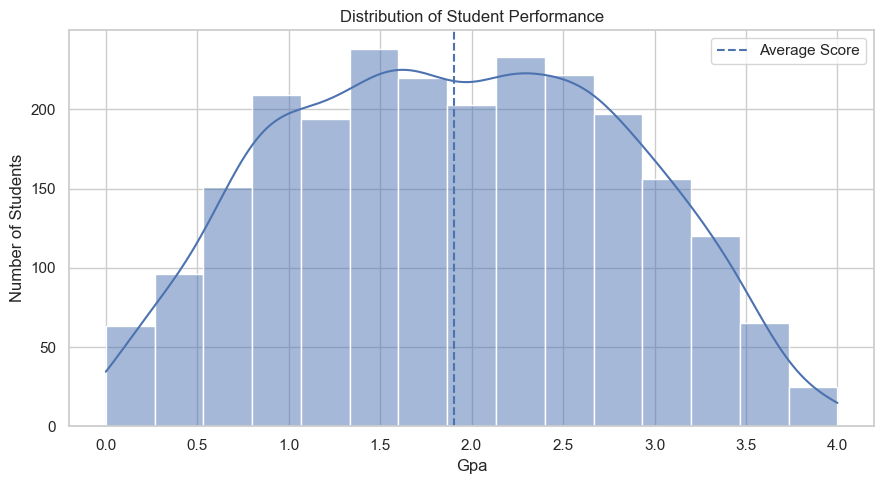

In [35]:
if TARGET_COL is not None:
    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=df_clean,
        x=TARGET_COL,
        bins=15,
        kde=True
    )

    plt.axvline(
        df_clean[TARGET_COL].mean(),
        linestyle="--",
        label="Average Score"
    )

    plt.title("Distribution of Student Performance")
    plt.xlabel(TARGET_COL.replace("_", " ").title())
    plt.ylabel("Number of Students")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "01_score_distribution.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

# Chart — Correlation heatmap

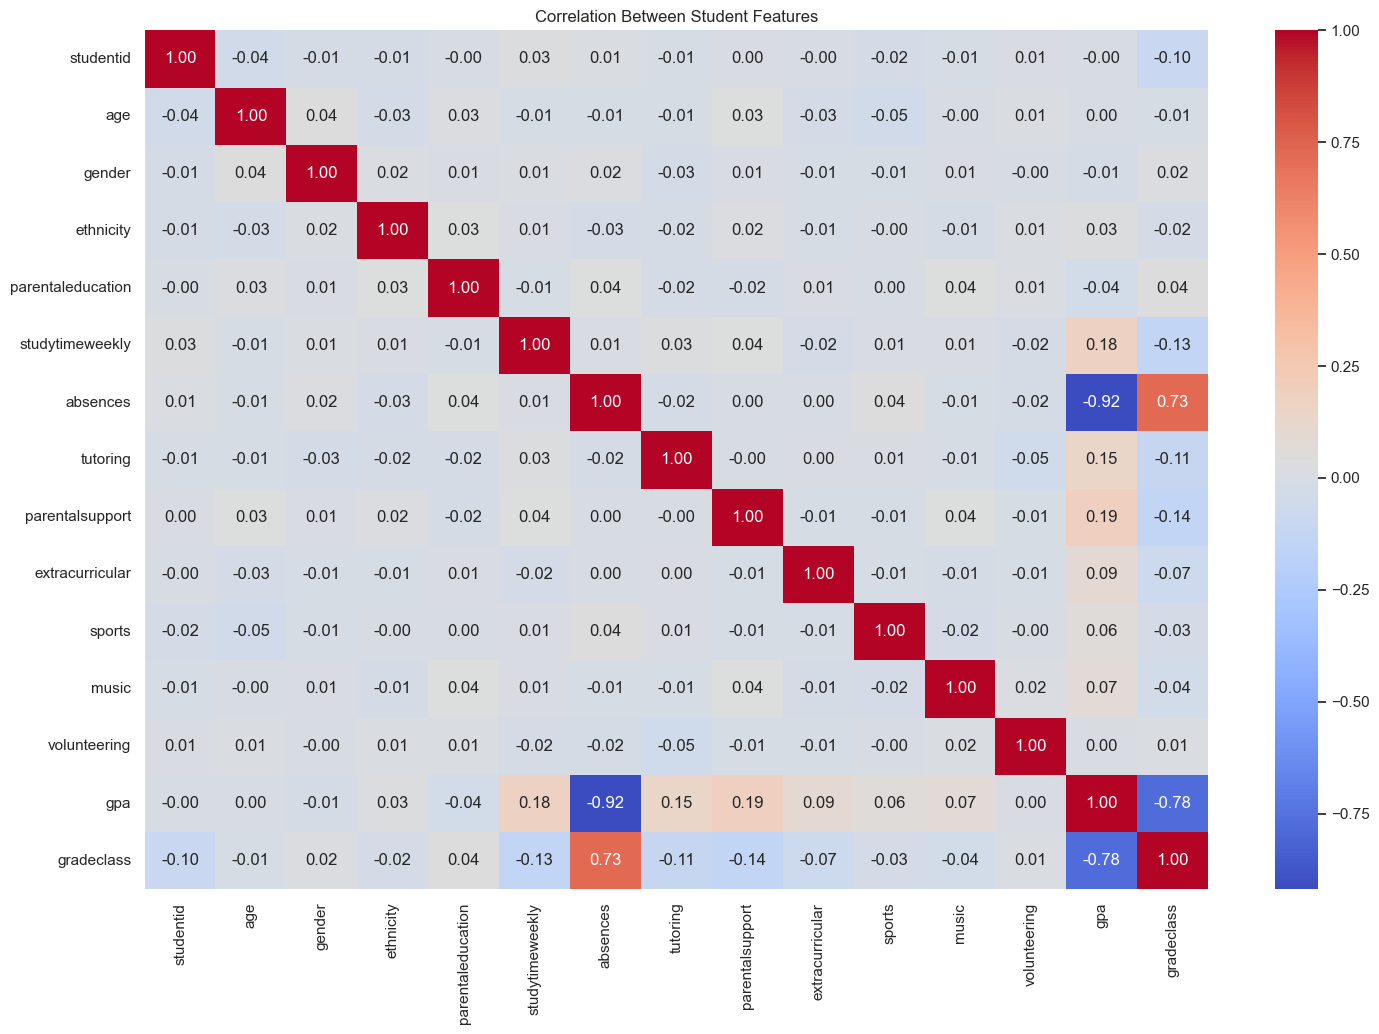

In [36]:
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

if len(numeric_cols) >= 2:
    correlation = df_clean[numeric_cols].corr()

    plt.figure(
        figsize=(
            max(8, len(numeric_cols)),
            max(6, len(numeric_cols) * 0.7)
        )
    )

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Between Student Features")
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "02_correlation_heatmap.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

# Chart — Performance by student category

In [37]:
categorical_cols = df_clean.select_dtypes(
    exclude=np.number
).columns.tolist()

group_cols = [
    col for col in categorical_cols
    if 2 <= df_clean[col].nunique() <= 15
]

if TARGET_COL is not None and group_cols:
    GROUP_COL = group_cols[0]

    group_summary = (
        df_clean.groupby(GROUP_COL, observed=True)[TARGET_COL]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=group_summary.index.astype(str),
        y=group_summary.values
    )

    plt.title(
        f"Average {TARGET_COL} by {GROUP_COL}"
    )
    plt.xlabel(GROUP_COL.replace("_", " ").title())
    plt.ylabel(f"Average {TARGET_COL}")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "03_group_performance.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    display(group_summary.to_frame("Average Score"))
else:
    print("Suitable performance and category columns were not found.")

Suitable performance and category columns were not found.


# Chart — Numeric features vs. performance

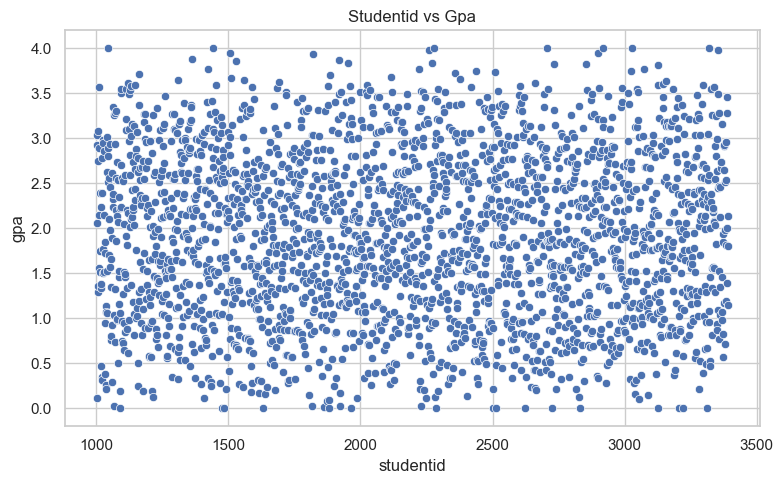

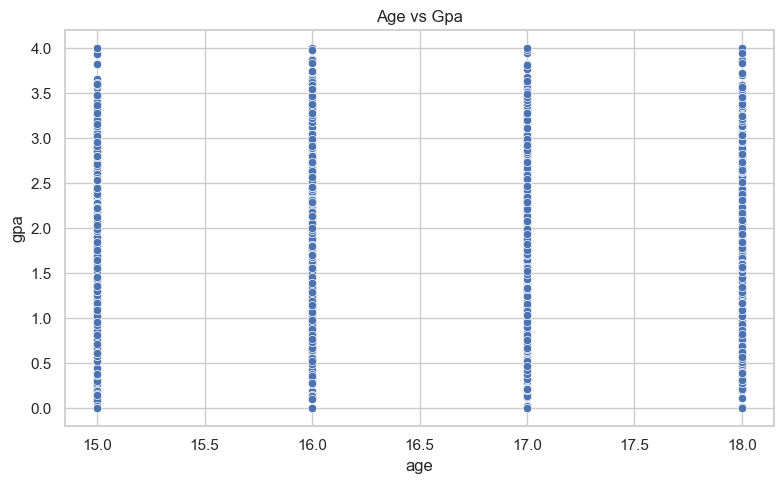

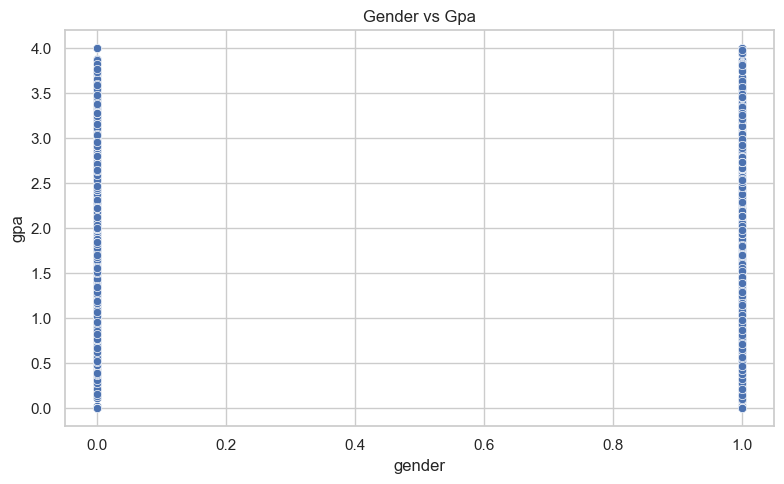

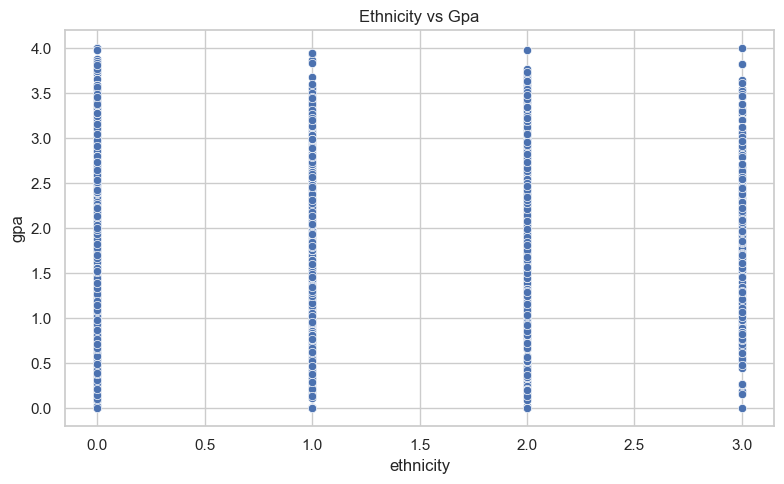

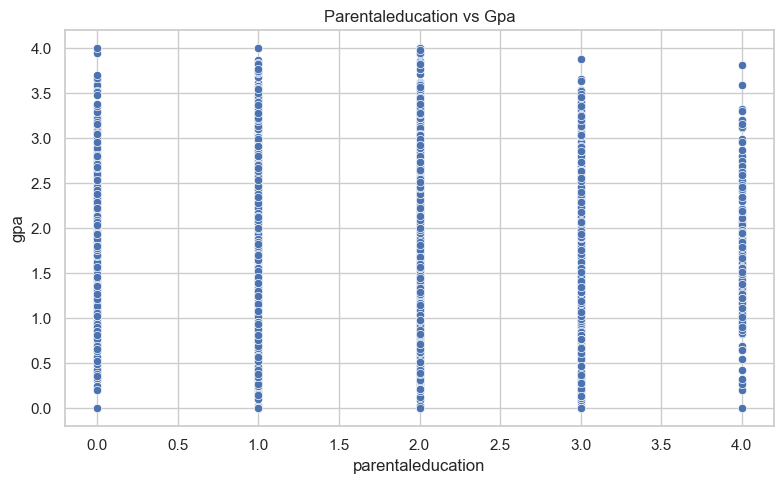

In [38]:
if TARGET_COL is not None:
    other_numeric_cols = [
        col for col in numeric_cols
        if col != TARGET_COL
    ]

    for feature in other_numeric_cols[:5]:
        plt.figure(figsize=(8, 5))

        sns.scatterplot(
            data=df_clean,
            x=feature,
            y=TARGET_COL
        )

        plt.title(
            f"{feature.replace('_', ' ').title()} "
            f"vs {TARGET_COL.replace('_', ' ').title()}"
        )

        plt.tight_layout()

        filename = f"comparison_{feature}.png"

        plt.savefig(
            OUTPUT_DIR / filename,
            dpi=150,
            bbox_inches="tight"
        )

        plt.show()

# Generate insights

In [39]:
insights = []

insights.append(
    f"The cleaned dataset contains {len(df_clean)} records."
)

insights.append(
    f"A total of {duplicates_removed} duplicate rows were removed."
)

if TARGET_COL is not None:
    mean_score = df_clean[TARGET_COL].mean()
    median_score = df_clean[TARGET_COL].median()

    insights.append(
        f"Average performance: {mean_score:.2f}."
    )

    insights.append(
        f"Median performance: {median_score:.2f}."
    )

    if len(numeric_cols) > 1:
        correlations = (
            df_clean[numeric_cols]
            .corr()[TARGET_COL]
            .drop(TARGET_COL)
            .dropna()
        )

        if not correlations.empty:
            strongest_feature = correlations.abs().idxmax()

            insights.append(
                f"The strongest absolute linear correlation with "
                f"{TARGET_COL} is {strongest_feature}, "
                f"with correlation {correlations[strongest_feature]:.2f}."
            )

print("KEY INSIGHTS")
print("=" * 40)

for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

print("\nRECOMMENDATIONS")
print("1. Review students who may need additional academic support.")
print("2. Investigate patterns in attendance and study habits if available.")
print("3. Use evidence to guide learning support.")
print("4. Correlation does not prove cause and effect.")

KEY INSIGHTS
1. The cleaned dataset contains 2392 records.
2. A total of 0 duplicate rows were removed.
3. Average performance: 1.91.
4. Median performance: 1.89.
5. The strongest absolute linear correlation with gpa is absences, with correlation -0.92.

RECOMMENDATIONS
1. Review students who may need additional academic support.
2. Investigate patterns in attendance and study habits if available.
3. Use evidence to guide learning support.
4. Correlation does not prove cause and effect.


# Test data quality

In [40]:
tests = {
    "Dataset is not empty": len(df_clean) > 0,
    "No duplicate rows": not df_clean.duplicated().any(),
    "No missing values": not df_clean.isnull().any().any(),
    "Column names are unique": df_clean.columns.is_unique
}

if TARGET_COL is not None:
    tests["Performance column is numeric"] = (
        pd.api.types.is_numeric_dtype(df_clean[TARGET_COL])
    )

print("DATA QUALITY TEST RESULTS")
print("=" * 40)

for name, result in tests.items():
    print(f"{'PASS' if result else 'FAIL'}: {name}")

assert all(tests.values()), "Some data-quality tests failed."

DATA QUALITY TEST RESULTS
PASS: Dataset is not empty
PASS: No duplicate rows
PASS: No missing values
PASS: Column names are unique
PASS: Performance column is numeric


# Export cleaned dataset

In [41]:
cleaned_path = (
    OUTPUT_DIR / "cleaned_student_performance.csv"
)

df_clean.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved successfully!")
print("Location:", cleaned_path.resolve())

Cleaned dataset saved successfully!
Location: C:\Users\amans\Downloads\Student_Performance_Analysis_Output\cleaned_student_performance.csv


# Generate the final report

In [42]:
report_lines = [
    "STUDENT PERFORMANCE ANALYSIS REPORT",
    "=" * 45,
    f"Generated on: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
    f"Source file: {DATA_PATH.name}",
    "",
    "1. PROJECT OVERVIEW",
    "Analysis of student academic performance using Python.",
    "",
    "2. DATASET SUMMARY",
    f"Total records: {len(df_clean)}",
    f"Total columns: {len(df_clean.columns)}",
    f"Duplicate rows removed: {duplicates_removed}",
    "",
    "3. PERFORMANCE ANALYSIS",
    f"Performance column: {TARGET_COL}",
]

if TARGET_COL is not None:
    report_lines.extend([
        f"Average score: {df_clean[TARGET_COL].mean():.2f}",
        f"Median score: {df_clean[TARGET_COL].median():.2f}",
        f"Maximum score: {df_clean[TARGET_COL].max():.2f}",
        f"Minimum score: {df_clean[TARGET_COL].min():.2f}",
    ])

report_lines.extend([
    "",
    "4. KEY INSIGHTS",
    *[f"- {item}" for item in insights],
    "",
    "5. TESTING RESULTS",
    *[
        f"- {'PASS' if result else 'FAIL'}: {name}"
        for name, result in tests.items()
    ],
    "",
    "6. DATA CLEANING",
    "- Standardized column names.",
    "- Removed duplicate records.",
    "- Handled missing values.",
    "- Checked likely score and percentage columns.",
    "",
    "7. LIMITATIONS",
    "- Findings depend on the quality of the input data.",
    "- Missing values were imputed.",
    "- Score validation assumes a 0–100 scale for relevant columns.",
    "- Correlation does not prove causation.",
    "",
    "8. CONCLUSION",
    "The project provides a reproducible workflow for cleaning, "
    "analyzing, visualizing, testing, and reporting student data."
])

report = "\n".join(report_lines)

report_path = OUTPUT_DIR / "student_performance_report.txt"

report_path.write_text(
    report,
    encoding="utf-8"
)

print(report)
print("\nReport saved:", report_path.resolve())

STUDENT PERFORMANCE ANALYSIS REPORT
Generated on: 2026-10-21 21:11:06
Source file: Student_performance_data _.csv

1. PROJECT OVERVIEW
Analysis of student academic performance using Python.

2. DATASET SUMMARY
Total records: 2392
Total columns: 15
Duplicate rows removed: 0

3. PERFORMANCE ANALYSIS
Performance column: gpa
Average score: 1.91
Median score: 1.89
Maximum score: 4.00
Minimum score: 0.00

4. KEY INSIGHTS
- The cleaned dataset contains 2392 records.
- A total of 0 duplicate rows were removed.
- Average performance: 1.91.
- Median performance: 1.89.
- The strongest absolute linear correlation with gpa is absences, with correlation -0.92.

5. TESTING RESULTS
- PASS: Dataset is not empty
- PASS: No duplicate rows
- PASS: No missing values
- PASS: Column names are unique
- PASS: Performance column is numeric

6. DATA CLEANING
- Standardized column names.
- Removed duplicate records.
- Handled missing values.
- Checked likely score and percentage columns.

7. LIMITATIONS
- Finding

# Final project verification

In [43]:
required_files = [
    OUTPUT_DIR / "cleaned_student_performance.csv",
    OUTPUT_DIR / "student_performance_report.txt"
]

print("FINAL PROJECT VERIFICATION")
print("=" * 40)

for file in required_files:
    print(
        f"{'PASS' if file.exists() else 'FAIL'}: {file.name}"
    )

charts = list(OUTPUT_DIR.glob("*.png"))

print("Total charts generated:", len(charts))

assert all(file.exists() for file in required_files)

print("\nProject completed successfully!")
print("Output folder:", OUTPUT_DIR.resolve())

FINAL PROJECT VERIFICATION
PASS: cleaned_student_performance.csv
PASS: student_performance_report.txt
Total charts generated: 8

Project completed successfully!
Output folder: C:\Users\amans\Downloads\Student_Performance_Analysis_Output
